# Decision Trees

Decision trees are a **non-parametric** supervised learning method (they don't assume a fixed form for the relationship: the more data, the more splits a tree can make) used for both classification and regression tasks.

Decision trees where the target variable can take a finite set of values are called **classification trees**; in these tree structures, the leaves represent **class labels** and the branches represent features that lead to those class labels. Decision trees where the target variable can take continuous values (typically real numbers) are called **regression trees**.

**Advantages:**
- Can be displayed graphically and are easily interpreted.
- Needs little preprocessing: each split compares one feature with a threshold, so the scale of the features doesn't matter. The algorithm could split on categories directly, but scikit-learn's implementation needs them encoded as numbers first.

**Disadvantages:**
- A single tree is usually less accurate than other models. Ensembles of many trees, such as [random forests](random_forests.ipynb) and [gradient boosting](gradient_boosting.ipynb), are among the most accurate models for tables.
- Not robust. A small change in the data can cause a large difference in the final tree.

`Scikit-learn` uses the CART algorithm (*Classification and Regression Trees*), which produces only **binary trees** (non-leaf nodes have only two children). However, other algorithms such as ID3 can produce decision trees with nodes having more than 2 children.

## Decision Trees for Classification

`scikit-learn` provides the `DecisionTreeClassifier` class to fit a decision tree model to a dataset.

In [ ]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier

iris = load_iris()
X = iris.data
y = iris.target

tree_clf = DecisionTreeClassifier(random_state=42).fit(X, y)

scikit-learn's `plot_tree` draws the tree. It is one of the most interpretable models that exist: at each node a condition is evaluated, and one of the two paths is followed.

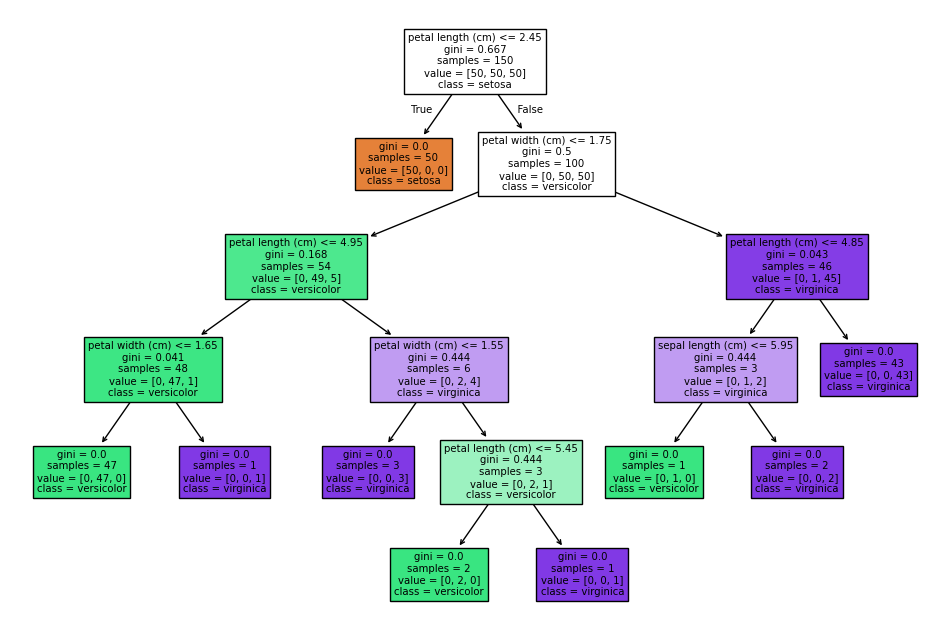

In [ ]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 8))  # Increase the figure size
plot_tree(tree_clf,
        feature_names=iris.feature_names,
        class_names=list(iris.target_names),
        filled=True)
plt.show()

## How a Tree Chooses Its Splits

The tree is grown from the top. At each node, the algorithm tries every feature and every threshold, and keeps the split that leaves the two groups as **pure** as possible, as measured by their **impurity**:

- In classification, scikit-learn measures it by default with the **Gini index**: the probability that two samples drawn at random from the node (with replacement) belong to different classes. It is 0 when all the samples of the node are of one class, and 0.667 at the root of this tree, where the three species are a third each.
- In regression, with the **squared error**: the mean of the squared differences between the node's targets and their mean, which is what the node predicts.

Each box of the drawing shows its node's impurity (`gini` or `squared_error`), how many training samples reached it (`samples`), and how many of each class there are among them or their mean target (`value`). A node stops splitting when it is pure, or when a limit such as `max_depth` stops it. The same impurity is what [random forests](random_forests.ipynb) use to measure which features matter.

## Decision Trees for Regression

Decision trees can be used for both classification and regression tasks. These two problem categories differ in the nature of the target variable. In the case of classification, the target variable is categorical, while in the case of regression, the target variable is numeric or continuous.

Decision trees for classification and for regression are built by the same procedure, with a different measure of impurity, and the way predictions are made is different. In the case of classification, the prediction is made by assigning the most frequent class in the terminal node. **In the case of regression, the prediction is made by calculating the average of the observations in the training set** that belong to the same terminal node.

A regression tree divides the range of the input features into intervals and predicts a constant in each one: its predictions form a staircase.

A regression tree on the same simulated salaries as in [Linear regression](../linear-models/linear_regression.ipynb), 30 employees with their years of experience:

In [ ]:
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeRegressor

rng = np.random.default_rng(seed=42)
years = rng.uniform(0, 12, size=30).round(1)
salary = 22_000 + 2_600 * years + rng.normal(0, 4_000, size=30)
df = pd.DataFrame({"YearsExperience": years, "Salary": salary.round(-2)})

tree_reg = DecisionTreeRegressor(max_depth=3, random_state=42).fit(df[["YearsExperience"]], df["Salary"])

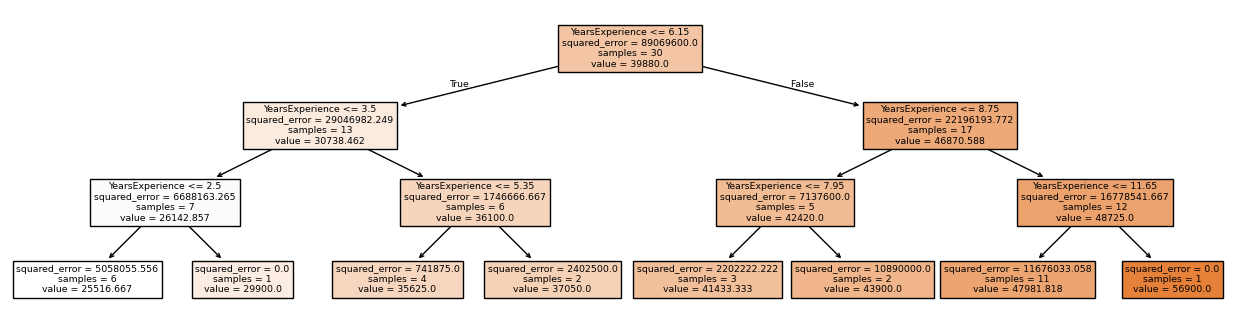

In [ ]:
plt.figure(figsize=(16, 4))
plot_tree(tree_reg, filled=True, feature_names=["YearsExperience"])
plt.show()

## Comparison with Linear Regression and Overfitting

If we apply a regression tree to the same dataset we used for linear regression, we can observe that the regression tree follows these points much more closely. This is because the regression tree is capable of capturing non-linear relationships between the input features and the target variable. The problem with this is that it tends to **overfit** the data.

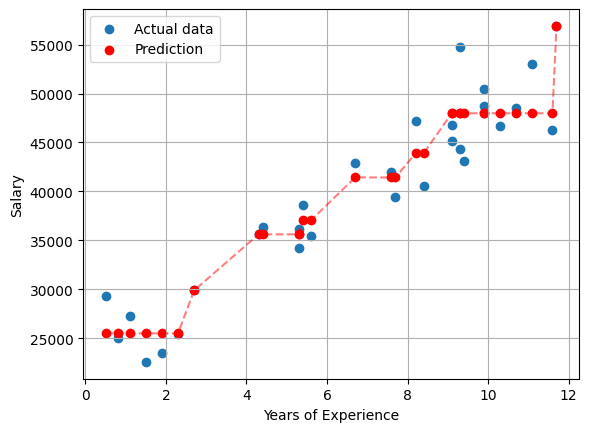

In [ ]:
plt.scatter(df['YearsExperience'], df['Salary'], label='Actual data')
df = df.sort_values(by=['YearsExperience'])
y_pred = tree_reg.predict(df[['YearsExperience']])
plt.scatter(df['YearsExperience'], y_pred, color='red', label='Prediction')
plt.plot(df['YearsExperience'], y_pred, color='red', linestyle='--', alpha=0.5)
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

The dashed line joins the predictions of the training points. Predicting for many points across the whole range shows the shape of the model, a staircase:

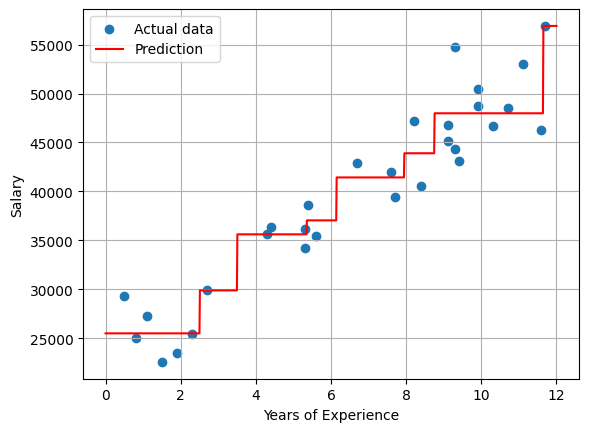

In [ ]:
grid = pd.DataFrame({'YearsExperience': np.linspace(0, 12, 1000)})

plt.scatter(df['YearsExperience'], df['Salary'], label='Actual data')
plt.plot(grid, tree_reg.predict(grid), color='red', label='Prediction')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

We can easily observe one of the main disadvantages of decision trees: their tendency to overfit the data. Decision trees tend to have high variance and, therefore, tend to overfit the data. This can be mitigated through tree pruning, limiting the depth of the tree, limiting the number of leaf nodes, or limiting the minimum number of samples required to split an internal node. In fact, we have used a decision tree with a maximum depth of only 3. Let's see what happens if we use a decision tree without limiting its depth.

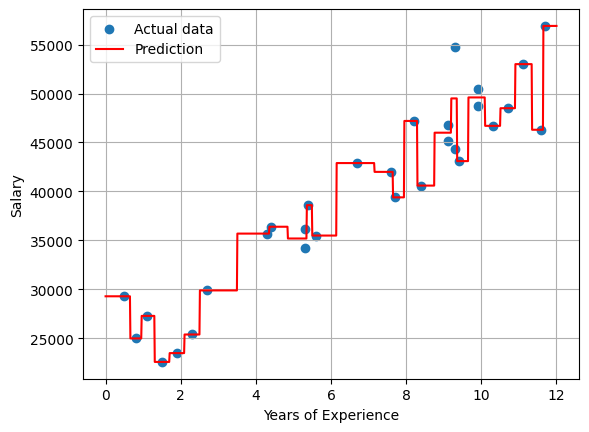

In [ ]:
tree_reg = DecisionTreeRegressor(random_state=42).fit(df[['YearsExperience']], df['Salary'])

plt.scatter(df['YearsExperience'], df['Salary'], label='Actual data')
plt.plot(grid, tree_reg.predict(grid), color='red', label='Prediction')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.legend()
plt.grid(True)
plt.show()

The decision tree continues making splits until each leaf is pure: a single sample, or samples that can't be told apart. This is a clear example of overfitting. However, a few samples don't coincide with their prediction. Each of them shares its years of experience with another employee who earns a different salary: a tree can't separate two rows with the same value of the feature, so it predicts their average. Let's confirm in which cases this occurs:

In [ ]:
repeated_years = df['YearsExperience'].value_counts()
repeated_years[repeated_years > 1]

YearsExperience
5.3    2
9.1    2
9.3    2
9.9    2
Name: count, dtype: int64

These plots show how closely the tree follows the employees it learned from. They can't show what matters: how wrong it would be for an employee it has never seen. Measuring that needs data held back from training: [Overfitting and the train/test split](../../ml-fundamentals/overfitting_and_the_split.ipynb).